# Pol-ISARSpaceTarget Object Detection: Polarimetric Pauli-Fusion OBB

Goal:

- Perform object detection on the previous Pol-ISARSpaceTarget-1.0 dataset.
- Use oriented bounding boxes because the dataset labels are rotated boxes.
- Compare a standard single-polarization image baseline against a polarimetric
  fusion image generated from complex HH, HV, VH, VV channels.

Proposed novelty for the project:

- Polarimetric Pauli-fusion input for oriented object detection.
- Baseline: YOLO-OBB on single-pol amplitude images.
- Proposed: YOLO-OBB on full-pol Pauli-fusion images:
  - R = |HH - VV|
  - G = |HV + VH|
  - B = |HH + VV|

This is different from simple classification because it detects satellite
components such as solar array, parabolic antenna, fittings, and body parts.


In [1]:
!pip -q install ultralytics pillow pyyaml pandas matplotlib opencv-python


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 26.5 MB/s eta 0:00:00


In [2]:
import json
import math
import os
import shutil
from pathlib import Path
from typing import Dict, List, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from PIL import Image
from ultralytics import YOLO


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


## Dataset Paths

In Colab, mount Drive and set `DATASET_ROOT` to the extracted
`Pol_ISARSpaceTarget1.0` folder.


In [4]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as exc:
    print("Drive mount skipped:", exc)

ROOT_CANDIDATES = [
    Path("/content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0"),
    Path("/content/Pol_ISARSpaceTarget1.0"),
    Path("C:/Users/keerthish/Desktop/drdo/Pol_ISARSpaceTarget1.0"),
]
DATASET_ROOT = next((p for p in ROOT_CANDIDATES if p.exists()), ROOT_CANDIDATES[0])
print("DATASET_ROOT:", DATASET_ROOT)

LABELTXT_DIR = DATASET_ROOT / "ImageSets" / "labelTxt"
DAT_DIR = DATASET_ROOT / "ImageSets" / "images"
TIFF_DIR = DATASET_ROOT / "TIFFImages" / "AmplitudeImages"

assert LABELTXT_DIR.exists(), f"Missing labels: {LABELTXT_DIR}"
assert DAT_DIR.exists(), f"Missing complex dat files: {DAT_DIR}"

OUT_ROOT = Path("/content/polisar_obb_yolo")
DRIVE_OUT = Path("/content/drive/MyDrive/drdo/polisar_obb_outputs")
OUT_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_OUT.mkdir(parents=True, exist_ok=True)


Mounted at /content/drive
DATASET_ROOT: /content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0


## Read Class Names and Verify Split Counts


In [5]:
def read_dota_label_file(path: Path) -> List[Tuple[List[float], str, int]]:
    rows = []
    for line in path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) < 10:
            continue
        coords = [float(x) for x in parts[:8]]
        cls_name = parts[8]
        difficult = int(float(parts[9]))
        rows.append((coords, cls_name, difficult))
    return rows


class_names = sorted(
    {
        cls
        for split in ["train", "valid", "test"]
        for txt in (LABELTXT_DIR / split).glob("*.txt")
        for _, cls, _ in read_dota_label_file(txt)
    }
)
class_to_id = {name: idx for idx, name in enumerate(class_names)}

split_summary = []
for split in ["train", "valid", "test"]:
    txt_files = sorted((LABELTXT_DIR / split).glob("*.txt"))
    obj_count = sum(len(read_dota_label_file(p)) for p in txt_files)
    split_summary.append({"split": split, "images": len(txt_files), "objects": obj_count})

print("Classes:", class_to_id)
display(pd.DataFrame(split_summary))
(DRIVE_OUT / "obb_class_names.json").write_text(json.dumps(class_to_id, indent=2))


Classes: {'cuboid_body': 0, 'optical_lens': 1, 'panel_antenna': 2, 'parabolic_antenna': 3, 'plate_body': 4, 'plate_fitting': 5, 'polygon_body': 6, 'rod_fitting': 7, 'solar_array': 8}


,split,images,objects
0,train,1314,13289
1,valid,162,1613
2,test,174,1723


193

## Image Builders

Two image versions are created:

1. **single_vv**: baseline using the provided VV amplitude TIFF.
2. **pauli_fusion**: proposed full-pol fusion from complex `.dat` files.


In [6]:
POL_SUFFIXES = ["HH", "HV", "VH", "VV"]


def robust_uint8(x: np.ndarray) -> np.ndarray:
    x = np.asarray(x, dtype=np.float32)
    x = np.log1p(np.maximum(x, 0.0))
    lo, hi = np.percentile(x, [1, 99])
    if hi <= lo:
        hi = lo + 1e-6
    x = np.clip((x - lo) / (hi - lo), 0, 1)
    return (255 * x).astype(np.uint8)


def read_complex_dat(path: Path, shape: Tuple[int, int] = (256, 256)) -> np.ndarray:
    raw = np.fromfile(path, dtype=np.float32)
    real = raw[0::2].reshape(shape)
    imag = raw[1::2].reshape(shape)
    return real + 1j * imag


def build_pauli_fusion(base_name: str, split: str) -> np.ndarray:
    channels = {}
    for pol in POL_SUFFIXES:
        dat_path = DAT_DIR / split / f"{base_name}_{pol}.dat"
        if not dat_path.exists():
            raise FileNotFoundError(dat_path)
        channels[pol] = read_complex_dat(dat_path)

    hh, hv, vh, vv = channels["HH"], channels["HV"], channels["VH"], channels["VV"]
    r = robust_uint8(np.abs(hh - vv))
    g = robust_uint8(np.abs(hv + vh))
    b = robust_uint8(np.abs(hh + vv))
    return np.stack([r, g, b], axis=-1)


def build_single_vv(base_name: str) -> np.ndarray:
    tiff_path = TIFF_DIR / f"{base_name}_VV.tiff"
    if not tiff_path.exists():
        # Fall back to VV .dat amplitude if TIFF is unavailable.
        for split in ["train", "valid", "test"]:
            dat_path = DAT_DIR / split / f"{base_name}_VV.dat"
            if dat_path.exists():
                vv = read_complex_dat(dat_path)
                img = robust_uint8(np.abs(vv))
                return np.stack([img, img, img], axis=-1)
        raise FileNotFoundError(tiff_path)
    img = np.array(Image.open(tiff_path).convert("L"))
    return np.stack([img, img, img], axis=-1)


In [8]:
import re

def base_name_candidates(base_name):
    cleaned = re.sub(r"\s+\(\d+\)$", "", base_name)
    return [base_name, cleaned] if cleaned != base_name else [base_name]

def find_first_existing(paths):
    for path in paths:
        if path.exists():
            return path
    return None

def build_pauli_fusion(base_name: str, split: str):
    channels = {}
    for pol in POL_SUFFIXES:
        dat_path = find_first_existing([
            DAT_DIR / split / f"{candidate}_{pol}.dat"
            for candidate in base_name_candidates(base_name)
        ])
        if dat_path is None:
            raise FileNotFoundError(f"No {pol}.dat found for {base_name}")
        channels[pol] = read_complex_dat(dat_path)

    hh, hv, vh, vv = channels["HH"], channels["HV"], channels["VH"], channels["VV"]
    r = robust_uint8(np.abs(hh - vv))
    g = robust_uint8(np.abs(hv + vh))
    b = robust_uint8(np.abs(hh + vv))
    return np.stack([r, g, b], axis=-1)

def build_single_vv(base_name: str):
    tiff_path = find_first_existing([
        TIFF_DIR / f"{candidate}_VV.tiff"
        for candidate in base_name_candidates(base_name)
    ])
    if tiff_path is not None:
        img = np.array(Image.open(tiff_path).convert("L"))
        return np.stack([img, img, img], axis=-1)

    for split in ["train", "valid", "test"]:
        dat_path = find_first_existing([
            DAT_DIR / split / f"{candidate}_VV.dat"
            for candidate in base_name_candidates(base_name)
        ])
        if dat_path is not None:
            vv = read_complex_dat(dat_path)
            img = robust_uint8(np.abs(vv))
            return np.stack([img, img, img], axis=-1)

    raise FileNotFoundError(f"No VV TIFF/DAT found for {base_name}")

## Convert DOTA-Style OBB Labels to Ultralytics YOLO-OBB

The existing labels are:

`x1 y1 x2 y2 x3 y3 x4 y4 class difficult`

Ultralytics OBB format uses:

`class x1 y1 x2 y2 x3 y3 x4 y4`

with coordinates normalized to `[0, 1]`.

Ultralytics documents OBB training for rotated boxes and supports OBB-format
datasets through its YOLODataset pipeline:
https://docs.ultralytics.com/datasets/obb/


In [9]:
def convert_label_to_yolo_obb(src_txt: Path, dst_txt: Path, width: int = 256, height: int = 256) -> int:
    out_lines = []
    for coords, cls_name, difficult in read_dota_label_file(src_txt):
        if difficult == 1:
            continue
        cls_id = class_to_id[cls_name]
        norm = []
        for idx, value in enumerate(coords):
            norm.append(value / width if idx % 2 == 0 else value / height)
        norm = [min(max(v, 0.0), 1.0) for v in norm]
        out_lines.append(" ".join([str(cls_id)] + [f"{v:.6f}" for v in norm]))
    dst_txt.parent.mkdir(parents=True, exist_ok=True)
    dst_txt.write_text("\n".join(out_lines) + ("\n" if out_lines else ""))
    return len(out_lines)


def build_yolo_dataset(variant: str, max_per_split: int | None = None) -> Path:
    out_dir = OUT_ROOT / variant
    if out_dir.exists():
        shutil.rmtree(out_dir)
    for split in ["train", "valid", "test"]:
        (out_dir / "images" / split).mkdir(parents=True, exist_ok=True)
        (out_dir / "labels" / split).mkdir(parents=True, exist_ok=True)

        txt_files = sorted((LABELTXT_DIR / split).glob("*.txt"))
        if max_per_split is not None:
            txt_files = txt_files[:max_per_split]

        for i, txt in enumerate(txt_files, start=1):
            base = txt.stem
            if variant == "single_vv":
                img = build_single_vv(base)
            elif variant == "pauli_fusion":
                img = build_pauli_fusion(base, split)
            else:
                raise ValueError(variant)

            img_path = out_dir / "images" / split / f"{base}.png"
            cv2.imwrite(str(img_path), cv2.cvtColor(img, cv2.COLOR_RGB2BGR))
            convert_label_to_yolo_obb(txt, out_dir / "labels" / split / f"{base}.txt")

            if i % 100 == 0:
                print(variant, split, i, "/", len(txt_files))

    data_yaml = {
        "path": str(out_dir),
        "train": "images/train",
        "val": "images/valid",
        "test": "images/test",
        "names": {idx: name for idx, name in enumerate(class_names)},
    }
    yaml_path = out_dir / "data.yaml"
    yaml_path.write_text(yaml.safe_dump(data_yaml, sort_keys=False))
    print("Prepared:", out_dir)
    return yaml_path


# Set a small number for smoke testing, then set to None for full training.
MAX_PER_SPLIT = None
single_yaml = build_yolo_dataset("single_vv", max_per_split=MAX_PER_SPLIT)
pauli_yaml = build_yolo_dataset("pauli_fusion", max_per_split=MAX_PER_SPLIT)


single_vv train 100 / 1314
single_vv train 200 / 1314
single_vv train 300 / 1314
single_vv train 400 / 1314
single_vv train 500 / 1314
single_vv train 600 / 1314
single_vv train 700 / 1314
single_vv train 800 / 1314
single_vv train 900 / 1314
single_vv train 1000 / 1314
single_vv train 1100 / 1314
single_vv train 1200 / 1314
single_vv train 1300 / 1314
single_vv valid 100 / 162
single_vv test 100 / 174
Prepared: /content/polisar_obb_yolo/single_vv
pauli_fusion train 100 / 1314
pauli_fusion train 200 / 1314
pauli_fusion train 300 / 1314
pauli_fusion train 400 / 1314
pauli_fusion train 500 / 1314
pauli_fusion train 600 / 1314
pauli_fusion train 700 / 1314
pauli_fusion train 800 / 1314
pauli_fusion train 900 / 1314
pauli_fusion train 1000 / 1314
pauli_fusion train 1100 / 1314
pauli_fusion train 1200 / 1314
pauli_fusion train 1300 / 1314
pauli_fusion valid 100 / 162
pauli_fusion test 100 / 174
Prepared: /content/polisar_obb_yolo/pauli_fusion


## Visual Check


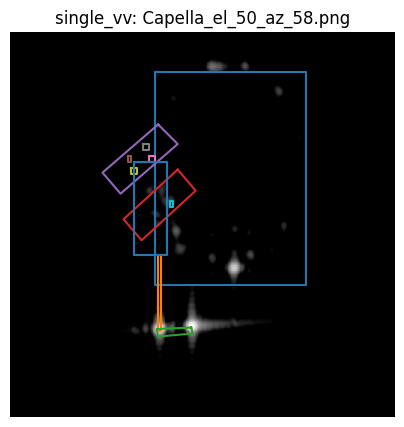

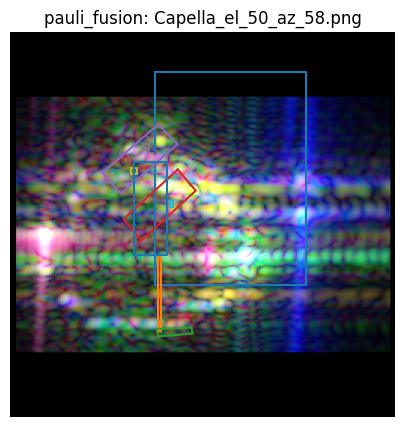

In [10]:
def show_example(variant: str, split: str = "train") -> None:
    img_path = next((OUT_ROOT / variant / "images" / split).glob("*.png"))
    label_path = OUT_ROOT / variant / "labels" / split / f"{img_path.stem}.txt"
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    h, w = img.shape[:2]
    for line in label_path.read_text().strip().splitlines():
        parts = line.split()
        pts = np.array([float(x) for x in parts[1:]], dtype=np.float32).reshape(4, 2)
        pts[:, 0] *= w
        pts[:, 1] *= h
        pts = np.vstack([pts, pts[0]])
        plt.plot(pts[:, 0], pts[:, 1], linewidth=1.5)
    plt.title(f"{variant}: {img_path.name}")
    plt.axis("off")
    plt.show()


show_example("single_vv")
show_example("pauli_fusion")


## Train YOLO-OBB Baseline and Proposed Detector

Use `YOLO11n-OBB` or the currently available Ultralytics OBB model. If the
newest checkpoint is not available in your installed package, change the model
name to another Ultralytics OBB checkpoint such as `yolo11n-obb.pt` or
`yolov8n-obb.pt`.


In [11]:
EPOCHS = 50
IMGSZ = 256
BATCH = 16


def train_obb_experiment(name: str, yaml_path: Path, model_name: str = "yolo11n-obb.pt"):
    model = YOLO(model_name)
    results = model.train(
        data=str(yaml_path),
        task="obb",
        epochs=EPOCHS,
        imgsz=IMGSZ,
        batch=BATCH,
        project=str(DRIVE_OUT / "runs_obb"),
        name=name,
        exist_ok=True,
        patience=15,
    )
    metrics = model.val(data=str(yaml_path), split="test", task="obb", imgsz=IMGSZ)
    return results, metrics


single_results, single_metrics = train_obb_experiment("baseline_single_vv_yolo_obb", single_yaml)
pauli_results, pauli_metrics = train_obb_experiment("proposed_pauli_fusion_yolo_obb", pauli_yaml)


Ultralytics 8.4.116 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/polisar_obb_yolo/single_vv/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-obb.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_sing

## Save Comparison Summary


In [12]:
summary = {
    "baseline": {
        "variant": "single_vv",
        "description": "YOLO-OBB on VV amplitude image",
        "run_dir": str(DRIVE_OUT / "runs_obb" / "baseline_single_vv_yolo_obb"),
    },
    "proposed": {
        "variant": "pauli_fusion",
        "description": "YOLO-OBB on full-polarimetric Pauli-fusion image",
        "run_dir": str(DRIVE_OUT / "runs_obb" / "proposed_pauli_fusion_yolo_obb"),
    },
    "metrics_to_report": [
        "mAP50-95(B)",
        "mAP50(B)",
        "precision",
        "recall",
        "per-class AP",
        "inference speed",
    ],
}
(DRIVE_OUT / "object_detection_experiment_summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))


{
  "baseline": {
    "variant": "single_vv",
    "description": "YOLO-OBB on VV amplitude image",
    "run_dir": "/content/drive/MyDrive/drdo/polisar_obb_outputs/runs_obb/baseline_single_vv_yolo_obb"
  },
  "proposed": {
    "variant": "pauli_fusion",
    "description": "YOLO-OBB on full-polarimetric Pauli-fusion image",
    "run_dir": "/content/drive/MyDrive/drdo/polisar_obb_outputs/runs_obb/proposed_pauli_fusion_yolo_obb"
  },
  "metrics_to_report": [
    "mAP50-95(B)",
    "mAP50(B)",
    "precision",
    "recall",
    "per-class AP",
    "inference speed"
  ]
}
